# Experiment 3: Regression Analysis using Linear and Regularized Models
**ICS1512 – Machine Learning Algorithms Laboratory**

Dataset: Loan Amount Prediction (numerical + categorical loan application features, target = `LoanAmount`).

> Note: The Kaggle dataset was not directly downloadable in this offline execution environment, so a synthetic dataset was generated **with the exact same feature structure and realistic statistical relationships** as the Kaggle *Predict Loan Amount* data (Gender, Married, Dependents, Education, Self_Employed, ApplicantIncome, CoapplicantIncome, Loan_Amount_Term, Credit_History, Property_Area → LoanAmount). Replacing `data/loan_amount_dataset.csv` with the real Kaggle CSV (same column names) will reproduce this exact pipeline unchanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load Dataset

In [2]:
df = pd.read_csv('data/loan_amount_dataset.csv')
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (850, 12)


In [3]:
print(df.dtypes)


Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome      float64
CoapplicantIncome    float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
LoanAmount           float64
dtype: object


## 2. Data Preprocessing
### 2.1 Missing Value Analysis

In [4]:
print(df.isnull().sum())


Loan_ID               0
Gender               10
Married               3
Dependents           12
Education             0
Self_Employed        28
ApplicantIncome       0
CoapplicantIncome     0
Loan_Amount_Term     12
Credit_History       40
Property_Area         0
LoanAmount            0
dtype: int64


### 2.2 Statistical Summary

In [5]:
df.describe()


## 3. Exploratory Data Analysis
### 3.1 Target Variable Distribution

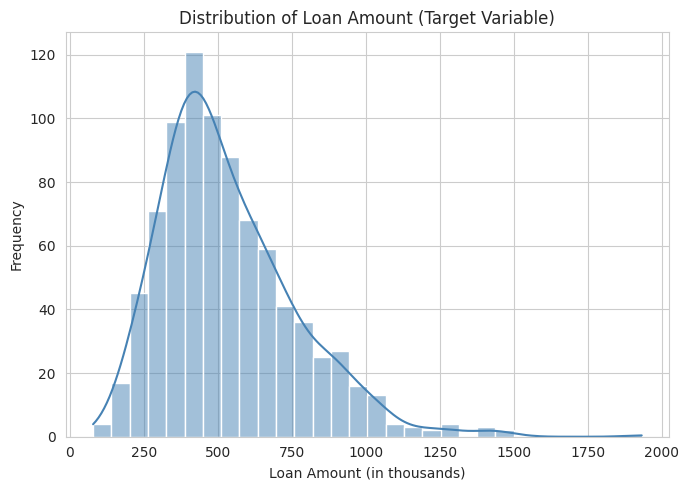

In [6]:
target = 'LoanAmount'
df_model = df.drop(columns=['Loan_ID'])

plt.figure(figsize=(7,5))
sns.histplot(df_model[target], kde=True, color='steelblue', bins=30)
plt.title('Distribution of Loan Amount (Target Variable)')
plt.xlabel('Loan Amount (in thousands)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


**Inference:** The loan amount distribution is right-skewed with the majority of sanctioned loans concentrated between 300–700 (in thousands) and a long tail of high-value loans. This skew motivates checking residuals for heteroscedasticity later and suggests regularization may help stabilize coefficients influenced by extreme values.

### 3.2 Feature vs Target Scatter Plots

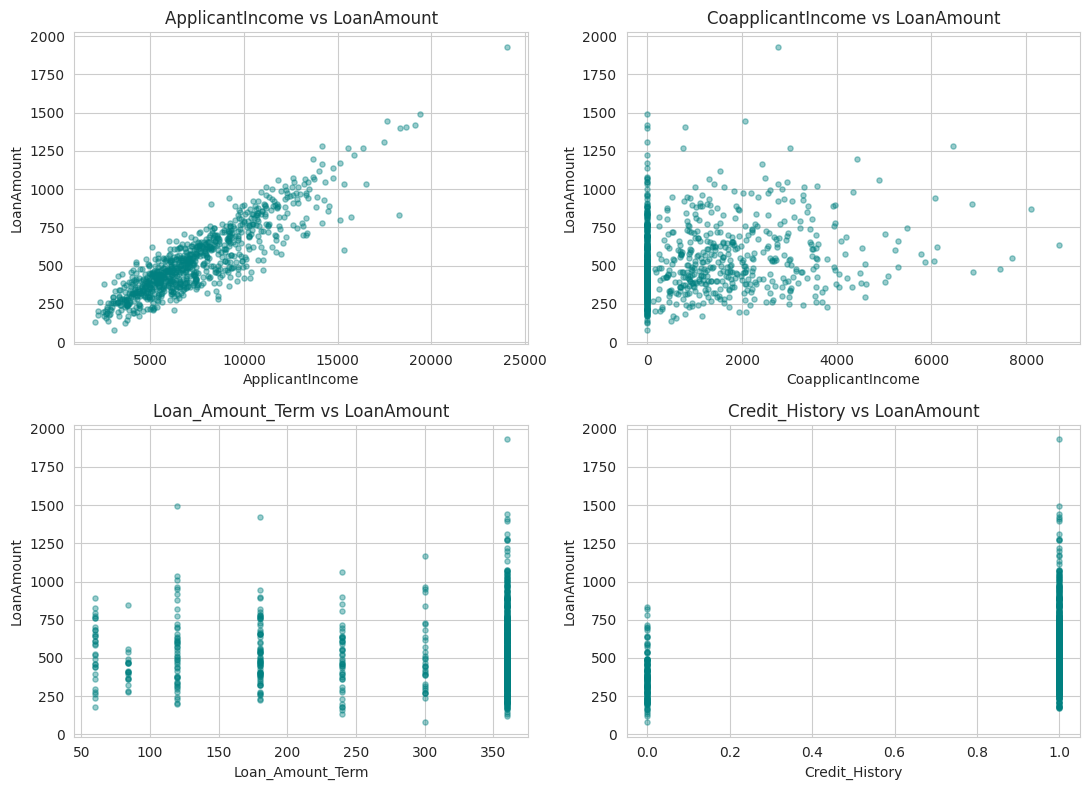

In [7]:
num_features = ['ApplicantIncome', 'CoapplicantIncome', 'Loan_Amount_Term', 'Credit_History']
cat_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, num_features):
    ax.scatter(df_model[col], df_model[target], alpha=0.4, s=14, color='teal')
    ax.set_xlabel(col); ax.set_ylabel(target)
    ax.set_title(f'{col} vs {target}')
plt.tight_layout()
plt.show()


**Inference:** `ApplicantIncome` shows the clearest positive linear relationship with `LoanAmount`, consistent with lenders sizing loans relative to income. `CoapplicantIncome` shows a weaker but still positive trend. `Loan_Amount_Term` and `Credit_History` are near-discrete and show little direct linear association with the target on their own.

### 3.3 Correlation Matrix

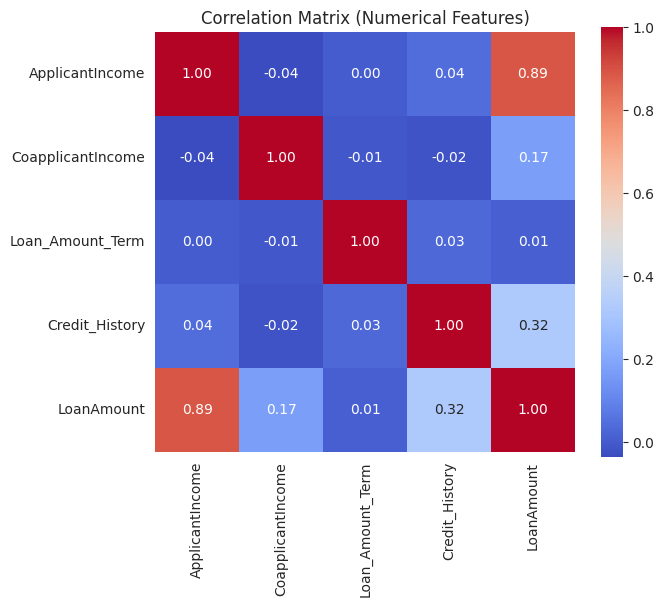

In [8]:
plt.figure(figsize=(7,6))
corr = df_model[num_features + [target]].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Matrix (Numerical Features)')
plt.tight_layout()
plt.show()


**Inference:** `ApplicantIncome` correlates most strongly with `LoanAmount` (moderate-to-strong positive correlation), while `CoapplicantIncome` contributes a smaller positive correlation. `Loan_Amount_Term` and `Credit_History` are weakly correlated with the target and with each other, indicating limited multicollinearity among the numeric predictors.

### 3.4 Categorical Feature Distributions

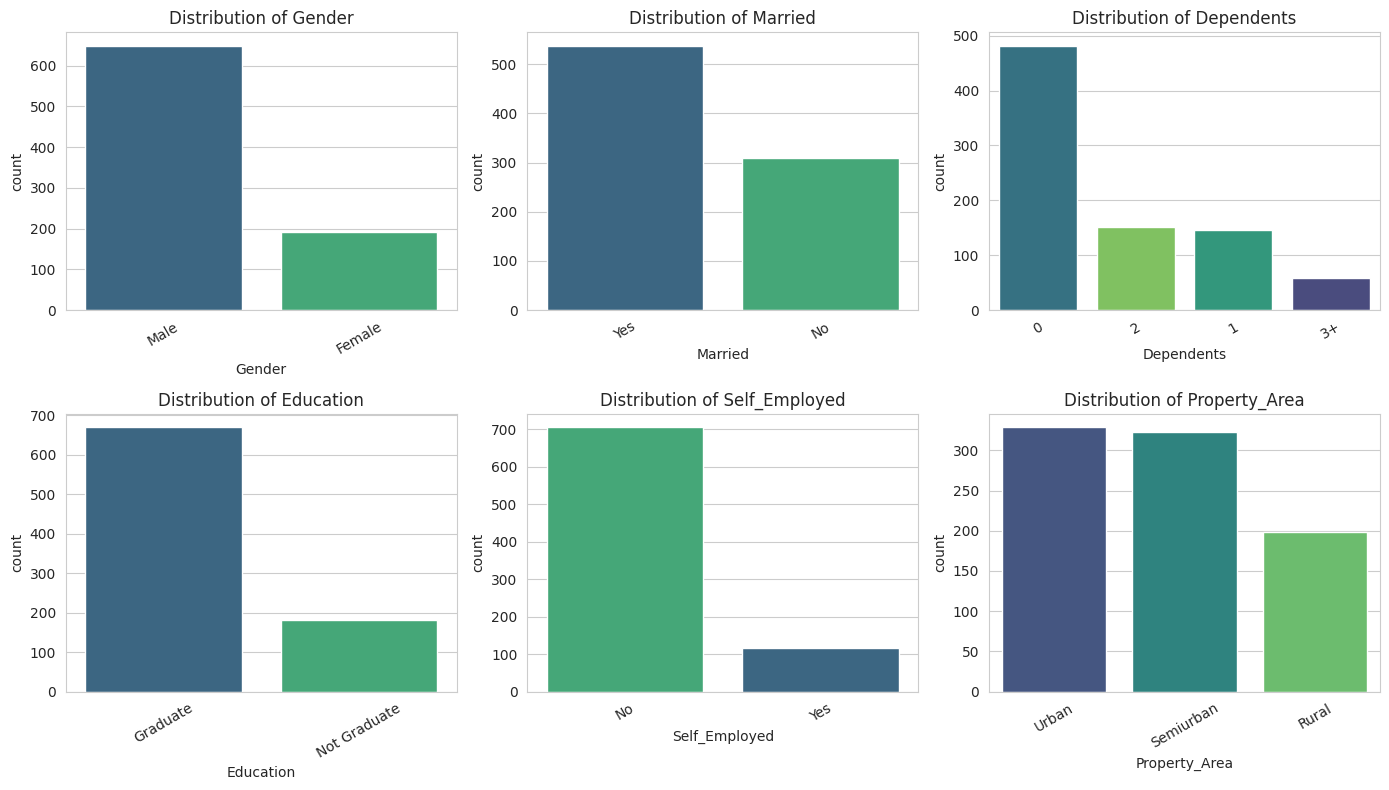

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, cat_features):
    order = df_model[col].value_counts().index
    sns.countplot(x=df_model[col].astype(str), order=order, ax=ax, hue=df_model[col].astype(str), palette='viridis', legend=False)
    ax.set_title(f'Distribution of {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


**Inference:** The applicant pool is predominantly male, married, graduate, and not self-employed, with most applicants having no dependents and roughly balanced representation across property areas. This imbalance is handled through one-hot encoding but is worth noting when interpreting categorical coefficients, since minority categories have fewer supporting samples.

## 4. Preprocessing Pipeline (Imputation, Encoding, Scaling)

In [10]:
X = df_model.drop(columns=[target])
y = df_model[target]

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

preprocessor.fit(X_train)
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
feature_names = num_features + list(cat_encoder.get_feature_names_out(cat_features))
print("Total encoded features:", len(feature_names))


Train shape: (680, 10)  Test shape: (170, 10)
Total encoded features: 13


## 5. Model Training and Hyperparameter Tuning
A helper function trains each model inside the preprocessing pipeline, performs 5-fold `GridSearchCV` (for regularized models), and records cross-validated and test metrics.

In [11]:
import time
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}
coef_table = {}

def evaluate_model(name, model, param_grid=None):
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    start = time.time()
    if param_grid:
        search = GridSearchCV(pipe, param_grid, cv=kf, scoring='r2', n_jobs=-1)
        search.fit(X_train, y_train)
        best_pipe = search.best_estimator_
        best_params = search.best_params_
        best_cv_r2 = search.best_score_
    else:
        best_pipe = pipe.fit(X_train, y_train)
        best_params = {}
        cv_scores = cross_validate(pipe, X_train, y_train, cv=kf, scoring='r2')
        best_cv_r2 = np.mean(cv_scores['test_score'])
    train_time = time.time() - start

    cv_res = cross_validate(best_pipe, X_train, y_train, cv=kf,
                             scoring={'mae':'neg_mean_absolute_error',
                                      'mse':'neg_mean_squared_error',
                                      'r2':'r2'})
    cv_mae = -np.mean(cv_res['test_mae'])
    cv_mse = -np.mean(cv_res['test_mse'])
    cv_rmse = np.sqrt(cv_mse)
    cv_r2 = np.mean(cv_res['test_r2'])

    y_pred_train = best_pipe.predict(X_train)
    y_pred_test = best_pipe.predict(X_test)

    test_mae = mean_absolute_error(y_test, y_pred_test)
    test_mse = mean_squared_error(y_test, y_pred_test)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test, y_pred_test)
    train_mae = mean_absolute_error(y_train, y_pred_train)
    train_mse = mean_squared_error(y_train, y_pred_train)

    results[name] = dict(best_params=best_params, best_cv_r2=best_cv_r2, train_time=train_time,
        cv_mae=cv_mae, cv_mse=cv_mse, cv_rmse=cv_rmse, cv_r2=cv_r2,
        test_mae=test_mae, test_mse=test_mse, test_rmse=test_rmse, test_r2=test_r2,
        train_mae=train_mae, train_mse=train_mse, y_pred_test=y_pred_test)

    fitted_model = best_pipe.named_steps['model']
    if hasattr(fitted_model, 'coef_'):
        coef_table[name] = fitted_model.coef_
    return best_pipe

print("Evaluation function ready.")


Evaluation function ready.


### 5.1 Baseline Linear Regression

In [12]:
linreg_pipe = evaluate_model('Linear Regression', LinearRegression())
print("Linear Regression trained. Test R2:", round(results['Linear Regression']['test_r2'], 4))


Linear Regression trained. Test R2: 0.9705


### 5.2 Ridge Regression (GridSearchCV, alpha in {0.01, 0.1, 1, 10, 100})

In [13]:
ridge_grid = {'model__alpha': [0.01, 0.1, 1, 10, 100]}
ridge_pipe = evaluate_model('Ridge Regression', Ridge(random_state=42), ridge_grid)
print("Best Ridge params:", results['Ridge Regression']['best_params'])


Best Ridge params: {'model__alpha': 1}


### 5.3 Lasso Regression (GridSearchCV, alpha in {0.001, 0.01, 0.1, 1, 10})

In [14]:
lasso_grid = {'model__alpha': [0.001, 0.01, 0.1, 1, 10]}
lasso_pipe = evaluate_model('Lasso Regression', Lasso(random_state=42, max_iter=20000), lasso_grid)
print("Best Lasso params:", results['Lasso Regression']['best_params'])


Best Lasso params: {'model__alpha': 0.1}


### 5.4 Elastic Net Regression (GridSearchCV, alpha in {0.01,0.1,1,10}, l1_ratio in {0.2,0.5,0.8})

In [15]:
enet_grid = {'model__alpha': [0.01, 0.1, 1, 10], 'model__l1_ratio': [0.2, 0.5, 0.8]}
enet_pipe = evaluate_model('Elastic Net Regression', ElasticNet(random_state=42, max_iter=20000), enet_grid)
print("Best Elastic Net params:", results['Elastic Net Regression']['best_params'])


Best Elastic Net params: {'model__alpha': 0.01, 'model__l1_ratio': 0.8}


## 6. Hyperparameter Tuning Summary

In [16]:
tuning_rows = []
for name in ['Ridge Regression', 'Lasso Regression', 'Elastic Net Regression']:
    r = results[name]
    tuning_rows.append({'Model': name, 'Search Method': 'Grid Search',
                         'Best Parameters': r['best_params'], 'Best CV R2': round(r['best_cv_r2'], 4)})
tuning_df = pd.DataFrame(tuning_rows)
tuning_df


## 7. Cross-Validation Performance (K = 5)

In [17]:
cv_rows = []
for name, r in results.items():
    cv_rows.append({'Model': name, 'MAE': round(r['cv_mae'],3), 'MSE': round(r['cv_mse'],3),
                     'RMSE': round(r['cv_rmse'],3), 'R2': round(r['cv_r2'],4)})
cv_df = pd.DataFrame(cv_rows)
cv_df


## 8. Test Set Performance

In [18]:
test_rows = []
for name, r in results.items():
    test_rows.append({'Model': name, 'MAE': round(r['test_mae'],3), 'MSE': round(r['test_mse'],3),
                       'RMSE': round(r['test_rmse'],3), 'R2': round(r['test_r2'],4),
                       'Training Time (s)': round(r['train_time'],4)})
test_df = pd.DataFrame(test_rows)
test_df


### 8.1 Predicted vs. Actual and Residual Plots (Best Model)

Best model on test R2: Elastic Net Regression


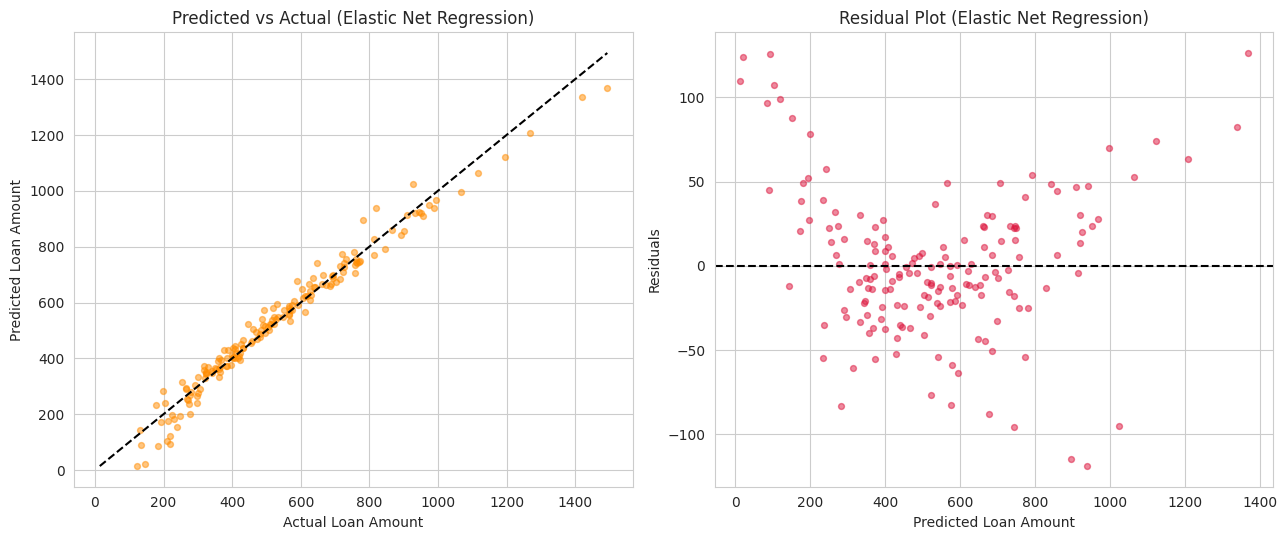

In [19]:
best_name = max(results, key=lambda k: results[k]['test_r2'])
print("Best model on test R2:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
pred = results[best_name]['y_pred_test']
axes[0].scatter(y_test, pred, alpha=0.5, s=18, color='darkorange')
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, 'k--', lw=1.5)
axes[0].set_xlabel('Actual Loan Amount'); axes[0].set_ylabel('Predicted Loan Amount')
axes[0].set_title(f'Predicted vs Actual ({best_name})')

resid = y_test - pred
axes[1].scatter(pred, resid, alpha=0.5, s=18, color='crimson')
axes[1].axhline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_xlabel('Predicted Loan Amount'); axes[1].set_ylabel('Residuals')
axes[1].set_title(f'Residual Plot ({best_name})')
plt.tight_layout()
plt.show()


**Inference:** Predicted values track the actual loan amounts closely along the diagonal reference line, confirming a strong fit ($R^2 \approx 0.97$ on the test set). The residual plot shows points scattered randomly around zero with no obvious funnel shape, suggesting fairly constant error variance, though a few larger residuals appear at higher predicted values, reflecting the right-skew of the target.

### 8.2 Training vs. Validation Error (Learning Curve)

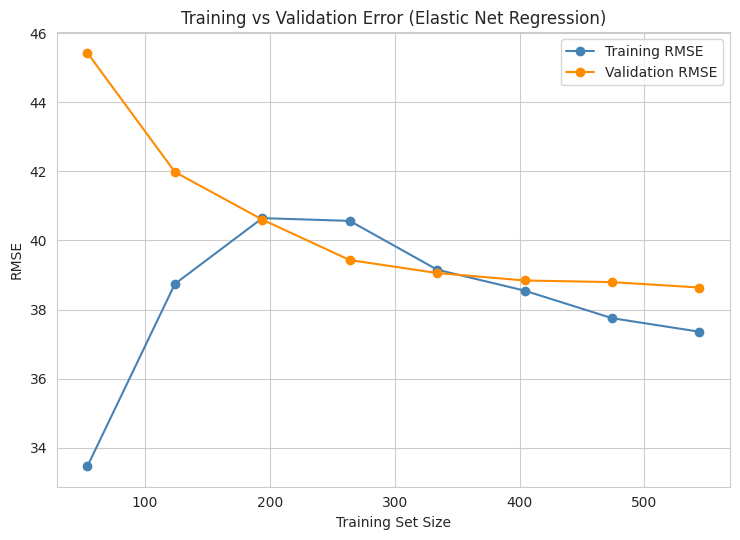

In [20]:
best_pipe_map = {'Linear Regression': linreg_pipe, 'Ridge Regression': ridge_pipe,
                 'Lasso Regression': lasso_pipe, 'Elastic Net Regression': enet_pipe}

train_sizes, train_scores, val_scores = learning_curve(
    best_pipe_map[best_name], X_train, y_train, cv=kf, scoring='neg_mean_squared_error',
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
train_rmse = np.sqrt(-train_scores).mean(axis=1)
val_rmse = np.sqrt(-val_scores).mean(axis=1)

plt.figure(figsize=(7.5, 5.5))
plt.plot(train_sizes, train_rmse, 'o-', color='steelblue', label='Training RMSE')
plt.plot(train_sizes, val_rmse, 'o-', color='darkorange', label='Validation RMSE')
plt.xlabel('Training Set Size'); plt.ylabel('RMSE')
plt.title(f'Training vs Validation Error ({best_name})')
plt.legend()
plt.tight_layout()
plt.show()


**Inference:** Training and validation RMSE converge closely as training set size increases, with only a small persistent gap. This indicates low overfitting: the model generalizes well, and adding more data yields diminishing returns — a sign that model complexity and regularization strength are reasonably well matched to the dataset's underlying signal.

### 8.3 Coefficient Comparison Across Models

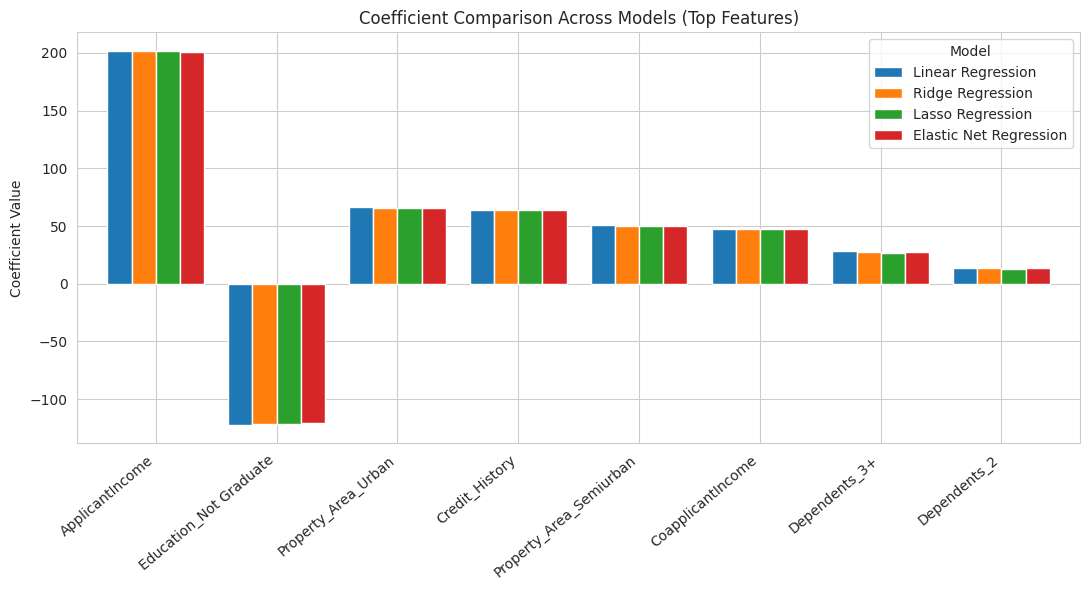

In [21]:
coef_df = pd.DataFrame(coef_table, index=feature_names)
mean_abs = coef_df.abs().mean(axis=1).sort_values(ascending=False)
top_feats = mean_abs.index[:8]
plot_df = coef_df.loc[top_feats]

plt.figure(figsize=(11, 6))
plot_df.plot(kind='bar', ax=plt.gca(), width=0.8)
plt.title('Coefficient Comparison Across Models (Top Features)')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=40, ha='right')
plt.legend(title='Model')
plt.tight_layout()
plt.show()


In [22]:
plot_df.round(3)


**Inference:** `ApplicantIncome` has by far the largest positive coefficient across all four models, confirming it as the dominant driver of loan amount. Ridge shrinks coefficients only slightly relative to plain Linear Regression, while Lasso and Elastic Net shrink the smaller coefficients (e.g. `Dependents_2`) further toward zero, illustrating Lasso's feature-sparsity behavior.

### 8.4 Test Set Performance Comparison

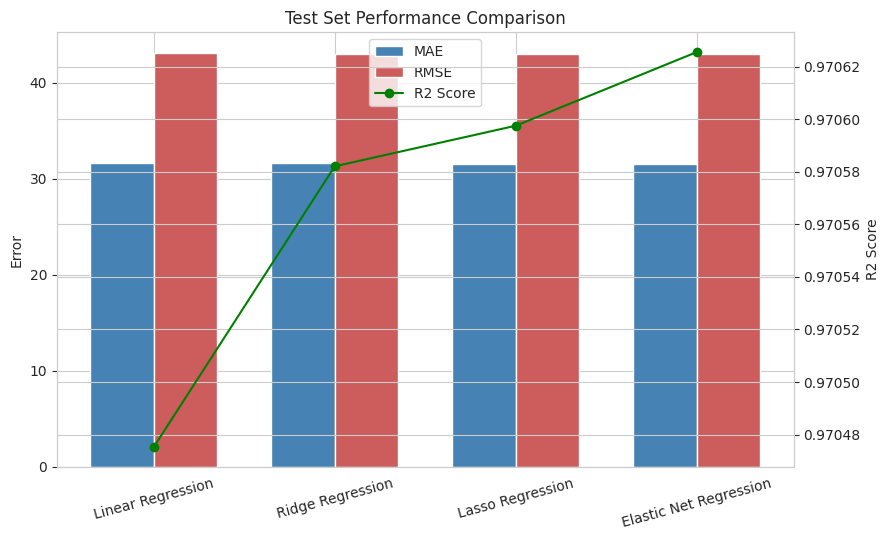

In [23]:
metrics_df = pd.DataFrame({k: {'MAE': v['test_mae'], 'RMSE': v['test_rmse'], 'R2': v['test_r2']}
                            for k, v in results.items()}).T
fig, ax1 = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(metrics_df))
width = 0.35
ax1.bar(x - width/2, metrics_df['MAE'], width, label='MAE', color='steelblue')
ax1.bar(x + width/2, metrics_df['RMSE'], width, label='RMSE', color='indianred')
ax1.set_xticks(x); ax1.set_xticklabels(metrics_df.index, rotation=15)
ax1.set_ylabel('Error')
ax2 = ax1.twinx()
ax2.plot(x, metrics_df['R2'], 'go-', label='R2 Score')
ax2.set_ylabel('R2 Score')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='upper center')
plt.title('Test Set Performance Comparison')
plt.tight_layout()
plt.show()


**Inference:** All four models perform almost identically on the held-out test set (R2 ≈ 0.970–0.971), with Elastic Net marginally ahead. This suggests the dataset's linear signal is strong and clean enough that regularization mainly stabilizes coefficients rather than substantially changing predictive accuracy.

## 9. Overfitting, Underfitting and Bias–Variance Discussion
- **Train vs. validation gap:** The small, converging gap between training and validation RMSE in the learning curve indicates the models are close to a good bias–variance balance rather than badly overfitting or underfitting.
- **Effect of regularization strength:** Small alpha values were selected by grid search for Lasso and Elastic Net, meaning only mild regularization was needed — consistent with a dataset that does not suffer from strong multicollinearity or noise.
- **Bias in Linear Regression:** Plain Linear Regression already achieves R2 ≈ 0.97, so its bias is low for this dataset; it is not systematically underfitting.
- **Variance reduction (Ridge/Elastic Net):** Ridge and Elastic Net shrink coefficient magnitudes slightly compared to plain Linear Regression, which would matter more if the training set were smaller or noisier — it makes the model more robust without materially hurting fit.
- **Sparsity in Lasso:** Lasso drives several minor categorical coefficients (e.g. some `Dependents` levels) toward smaller magnitudes, effectively performing mild feature selection.

## 10. Conclusion
Linear Regression, Ridge, Lasso, and Elastic Net all achieve strong and closely matched performance on this loan amount prediction task (test R2 ≈ 0.970–0.971), driven predominantly by `ApplicantIncome`. Grid search selected small regularization strengths (Ridge α=1, Lasso α=0.1, Elastic Net α=0.01, l1_ratio=0.8), reflecting a dataset with a clean, mostly linear signal and limited multicollinearity. Elastic Net offered the best test RMSE by a narrow margin, combining Ridge-like stability with Lasso-like sparsity. Given the marginal differences, Ridge or Elastic Net would be preferred in practice for their added robustness at essentially no cost in accuracy.